# Predicting IPO Listing Gains in the Indian Market with PyTorch

Dataquest guided project, *Predicting Listing Gains in the Indian IPO Market
Using PyTorch*.

When a company goes public it sets an issue price. On the first day of trading
the market decides what the shares are actually worth. A **listing gain** is a
first-day close above the issue price. This notebook builds a binary classifier
that predicts, from subscription and issue data known before listing, whether
an IPO will list at a gain.

The project asks for a deep network. It gets one. It also gets the question the
brief does not ask: **is the deep network actually better than a linear model
on 319 rows?** Section 10 answers that by rerunning the whole pipeline across
ten random splits, and the answer is no.

In [1]:
import copy
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, TensorDataset

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

print("torch", torch.__version__)

torch 2.14.1+cu130


## 1. Load the data

The file ships one quirk worth catching immediately: the first column is named
`"Date "` with a trailing space. Left alone it produces a `KeyError` on
`df['Date']` several cells later, where the cause is no longer obvious.

In [2]:
df = pd.read_csv("Indian_IPO_Market_Data.csv")
print("raw columns:", list(df.columns))

df.columns = [c.strip() for c in df.columns]
print("cleaned:    ", list(df.columns))
print()
print("shape:", df.shape)

raw columns: ['Date ', 'IPOName', 'Issue_Size', 'Subscription_QIB', 'Subscription_HNI', 'Subscription_RII', 'Subscription_Total', 'Issue_Price', 'Listing_Gains_Percent']
cleaned:     ['Date', 'IPOName', 'Issue_Size', 'Subscription_QIB', 'Subscription_HNI', 'Subscription_RII', 'Subscription_Total', 'Issue_Price', 'Listing_Gains_Percent']

shape: (319, 9)


In [3]:
df.head()

,Date,IPOName,Issue_Size,Subscription_QIB,Subscription_HNI,Subscription_RII,Subscription_Total,Issue_Price,Listing_Gains_Percent
0,03/02/10,Infinite Comp,189.80,48.44,106.02,11.08,43.22,165,11.82
1,08/02/10,Jubilant Food,328.70,59.39,51.95,3.79,31.11,145,-84.21
2,15/02/10,Syncom Health,56.25,0.99,16.60,6.25,5.17,75,17.13
3,15/02/10,Vascon Engineer,199.80,1.12,3.65,0.62,1.22,165,-11.28
4,19/02/10,Thangamayil,0.00,0.52,1.52,2.26,1.12,75,-5.20


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 319 entries, 0 to 318
Data columns (total 9 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Date                   319 non-null    str    
 1   IPOName                319 non-null    str    
 2   Issue_Size             319 non-null    float64
 3   Subscription_QIB       319 non-null    float64
 4   Subscription_HNI       319 non-null    float64
 5   Subscription_RII       319 non-null    float64
 6   Subscription_Total     319 non-null    float64
 7   Issue_Price            319 non-null    int64  
 8   Listing_Gains_Percent  319 non-null    float64
dtypes: float64(6), int64(1), str(2)
memory usage: 22.6 KB


In [5]:
df["Listing_Gains_Percent"].describe()

count    319.000000
mean       4.742696
std       47.650946
min      -97.150000
25%      -11.555000
50%        1.810000
75%       25.310000
max      270.400000
Name: Listing_Gains_Percent, dtype: float64

The target spread is enormous: a standard deviation of about 48 percentage
points on a mean near 5, with a worst case around -97% and a best case around
+270%. The median sits just above zero. Predicting the *size* of the gain from
six columns would be hopeless; predicting its *sign* is a reasonable question.

## 2. Build the binary target

`Listing_Gains_Profit` is 1 when the listing gain is positive and 0 otherwise.

For an investor the threshold at zero is the decision that matters: any
positive listing gain means the allocation was worth taking, and any negative
one means it was not. The size of the gain decides how much was made, but the
sign decides whether to participate at all.

In [6]:
df["Listing_Gains_Profit"] = (df["Listing_Gains_Percent"] > 0).astype(int)

counts = df["Listing_Gains_Profit"].value_counts().sort_index()
print(counts.to_string())
print()
print("profitable share: %.4f" % df["Listing_Gains_Profit"].mean())
print()
print("A classifier that always predicts 'profitable' scores %.2f%%."
      % (max(df['Listing_Gains_Profit'].mean(), 1 - df['Listing_Gains_Profit'].mean()) * 100))
print("That is the number anything below here has to beat to be worth running.")

Listing_Gains_Profit
0    145
1    174

profitable share: 0.5455

A classifier that always predicts 'profitable' scores 54.55%.
That is the number anything below here has to beat to be worth running.


Three columns cannot be used as predictors:

- `Listing_Gains_Percent` is the target in continuous form. Including it would
  leak the answer outright.
- `IPOName` is an identifier with 319 distinct values, so it can only be
  memorized.
- `Date` is a listing date. It could support a time-ordered split, which would
  be the honest design for a forecasting problem, but the project specifies a
  random stratified split and section 10 has something to say about that.

In [7]:
FEATURES = [
    "Issue_Size",
    "Subscription_QIB",
    "Subscription_HNI",
    "Subscription_RII",
    "Subscription_Total",
    "Issue_Price",
]
TARGET = "Listing_Gains_Profit"

print("features:", FEATURES)
print("dropped: ", ["Date", "IPOName", "Listing_Gains_Percent"])
print()
print("missing values anywhere:", int(df.isnull().sum().sum()))

features: ['Issue_Size', 'Subscription_QIB', 'Subscription_HNI', 'Subscription_RII', 'Subscription_Total', 'Issue_Price']
dropped:  ['Date', 'IPOName', 'Listing_Gains_Percent']

missing values anywhere: 0


## 3. Exploratory analysis

The question for each feature is simple: does it separate the two classes?

In [8]:
corr = (df[FEATURES + [TARGET]].corr()[TARGET]
        .drop(TARGET).sort_values(ascending=False))
print("Correlation with the target")
print(corr.round(4).to_string())

Correlation with the target
Subscription_QIB      0.3235
Subscription_Total    0.2833
Subscription_HNI      0.2719
Subscription_RII      0.2408
Issue_Price           0.0395
Issue_Size            0.0047


The four subscription measures carry essentially all of the signal, led by QIB
subscription at about 0.32. Qualified Institutional Buyers do the most research
before committing, so heavy institutional demand ahead of listing is the
closest thing here to informed opinion about the company.

`Issue_Size` and `Issue_Price` are near zero. How large the offering is, and
what it costs per share, say almost nothing about which way the stock moves on
day one.

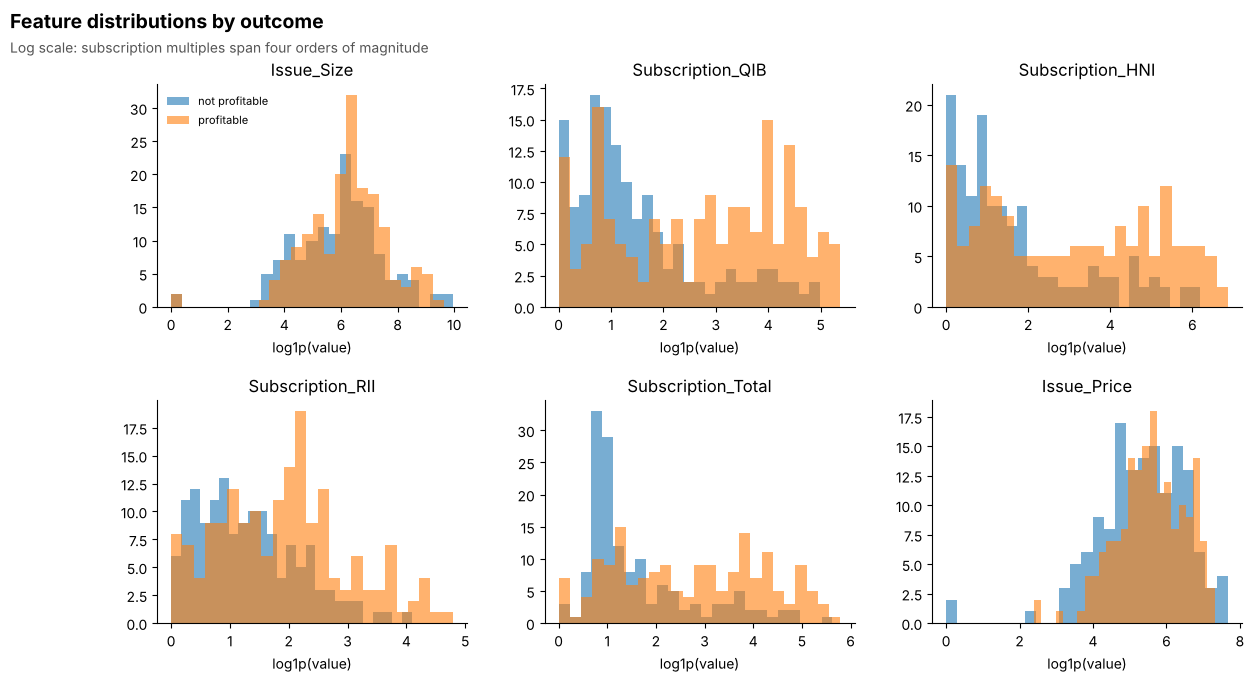

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, feature in zip(axes.ravel(), FEATURES):
    for label, name in [(0, "not profitable"), (1, "profitable")]:
        values = df.loc[df[TARGET] == label, feature]
        ax.hist(np.log1p(values), bins=25, alpha=0.6, label=name)
    ax.set_title(feature)
    ax.set_xlabel("log1p(value)")
    ax.spines[["top", "right"]].set_visible(False)
axes[0, 0].legend(fontsize=8, frameon=False)
fig.subplots_adjust(top=0.88, hspace=0.42, wspace=0.25)
fig.text(0.02, 0.96, "Feature distributions by outcome", fontsize=14, weight="bold")
fig.text(0.02, 0.925, "Log scale: subscription multiples span four orders of magnitude",
         fontsize=10, color="#555555")
plt.show()

The subscription features are plotted on a log scale because they span roughly
four orders of magnitude, from fractions of 1x to several hundred times
oversubscribed. On a linear axis every distribution collapses against the left
edge and the separation is invisible.

The profitable and unprofitable distributions overlap heavily on every feature.
There is a shift in the subscription measures, but nothing close to a clean
split, which already sets the ceiling on what any model can do here.

In [10]:
summary = df.groupby(TARGET)[FEATURES].median().T
summary.columns = ["not profitable", "profitable"]
summary["ratio"] = summary["profitable"] / summary["not profitable"]
print("Median feature value by outcome")
print(summary.round(3).to_string())

Median feature value by outcome
                    not profitable  profitable   ratio
Issue_Size                  450.00     540.260   1.201
Subscription_QIB              1.96      16.845   8.594
Subscription_HNI              2.09      21.970  10.512
Subscription_RII              2.32       6.035   2.601
Subscription_Total            2.06      16.395   7.959
Issue_Price                 220.00     272.000   1.236


## 4. Split and scale

A three-way split, stratified so each part keeps the 54.5% / 45.5% balance.
The scaler is fitted on the training split only: fitting it on everything would
leak the validation and test distributions into the transform, and the reported
scores would be optimistic for a reason no later check would catch.

In [11]:
X = df[FEATURES].values
y = df[TARGET].values

X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.25, stratify=y_temp, random_state=SEED)

print("train %d   val %d   test %d" % (len(X_train), len(X_val), len(X_test)))
print("positive rate  train %.3f   val %.3f   test %.3f"
      % (y_train.mean(), y_val.mean(), y_test.mean()))
print()
print("One test prediction is worth %.4f percentage points." % (100 / len(X_test)))
print("Keep that number in mind when reading any accuracy below.")

train 191   val 64   test 64
positive rate  train 0.545   val 0.547   test 0.547

One test prediction is worth 1.5625 percentage points.
Keep that number in mind when reading any accuracy below.


In [12]:
scaler = StandardScaler().fit(X_train)

X_train_t = torch.tensor(scaler.transform(X_train), dtype=torch.float32)
X_val_t = torch.tensor(scaler.transform(X_val), dtype=torch.float32)
X_test_t = torch.tensor(scaler.transform(X_test), dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.float32)
y_val_t = torch.tensor(y_val, dtype=torch.float32)
y_test_t = torch.tensor(y_test, dtype=torch.float32)

print("scaled train mean %.6f  std %.6f"
      % (X_train_t.mean().item(), X_train_t.std().item()))
print("scaled test  mean %.6f  std %.6f   (not exactly 0/1, which is correct:"
      % (X_test_t.mean().item(), X_test_t.std().item()))
print("the test set is transformed with the training set's statistics)")

scaled train mean -0.000000  std 1.000437
scaled test  mean 0.086176  std 1.293890   (not exactly 0/1, which is correct:
the test set is transformed with the training set's statistics)


## 5. Datasets and loaders

In [13]:
torch.manual_seed(SEED)

train_dataset = TensorDataset(X_train_t, y_train_t)
val_dataset = TensorDataset(X_val_t, y_val_t)
test_dataset = TensorDataset(X_test_t, y_test_t)

train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=16, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=16, shuffle=False)

batch_X, batch_y = next(iter(train_loader))
print("sample batch:", tuple(batch_X.shape), tuple(batch_y.shape))
print("train batches %d   val batches %d" % (len(train_loader), len(val_loader)))

sample batch: (16, 6) (16,)
train batches 12   val batches 4


## 6. The model

A funnel: 6 features into 32, then 16, then 8, then a single sigmoid output.

In [14]:
def make_model(input_size):
    return nn.Sequential(
        nn.Linear(input_size, 32), nn.ReLU(),
        nn.Linear(32, 16), nn.ReLU(),
        nn.Linear(16, 8), nn.ReLU(),
        nn.Linear(8, 1), nn.Sigmoid(),
    )


torch.manual_seed(SEED)
model = make_model(len(FEATURES))
print(model)

total_params = sum(p.numel() for p in model.parameters())
print()
print("trainable parameters: %d" % total_params)
print("training rows:        %d" % len(X_train))
print("parameters per training row: %.1f" % (total_params / len(X_train)))

Sequential(
  (0): Linear(in_features=6, out_features=32, bias=True)
  (1): ReLU()
  (2): Linear(in_features=32, out_features=16, bias=True)
  (3): ReLU()
  (4): Linear(in_features=16, out_features=8, bias=True)
  (5): ReLU()
  (6): Linear(in_features=8, out_features=1, bias=True)
  (7): Sigmoid()
)

trainable parameters: 897
training rows:        191
parameters per training row: 4.7


That last ratio is the first warning sign. The network carries several times
more free parameters than it has training examples to constrain them. Nothing
stops it fitting the training set perfectly and learning nothing transferable,
which is exactly what sections 7 and 8 are about.

## 7. Training the unregularized model

In [15]:
def accuracy(model, features, labels):
    model.eval()
    with torch.no_grad():
        probs = model(features).squeeze()
        return ((probs > 0.5).float() == labels).float().mean().item() * 100


torch.manual_seed(SEED)
model = make_model(len(FEATURES))
criterion = nn.BCELoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

base_train_accs, base_val_accs = [], []
for epoch in range(100):
    model.train()
    for bx, by in train_loader:
        optimizer.zero_grad()
        loss = criterion(model(bx).squeeze(), by)
        loss.backward()
        optimizer.step()
    base_train_accs.append(accuracy(model, X_train_t, y_train_t))
    base_val_accs.append(accuracy(model, X_val_t, y_val_t))
    if (epoch + 1) % 20 == 0:
        print("epoch %3d   train %.2f   val %.2f"
              % (epoch + 1, base_train_accs[-1], base_val_accs[-1]))

print()
print("final train %.2f   val %.2f   gap %.2f"
      % (base_train_accs[-1], base_val_accs[-1],
         base_train_accs[-1] - base_val_accs[-1]))
print("best val %.2f at epoch %d"
      % (max(base_val_accs), int(np.argmax(base_val_accs)) + 1))
print("test %.2f" % accuracy(model, X_test_t, y_test_t))

epoch  20   train 66.49   val 65.62


epoch  40   train 69.11   val 65.62


epoch  60   train 70.16   val 65.62


epoch  80   train 71.20   val 62.50


epoch 100   train 72.77   val 67.19

final train 72.77   val 67.19   gap 5.59
best val 67.19 at epoch 24
test 60.94


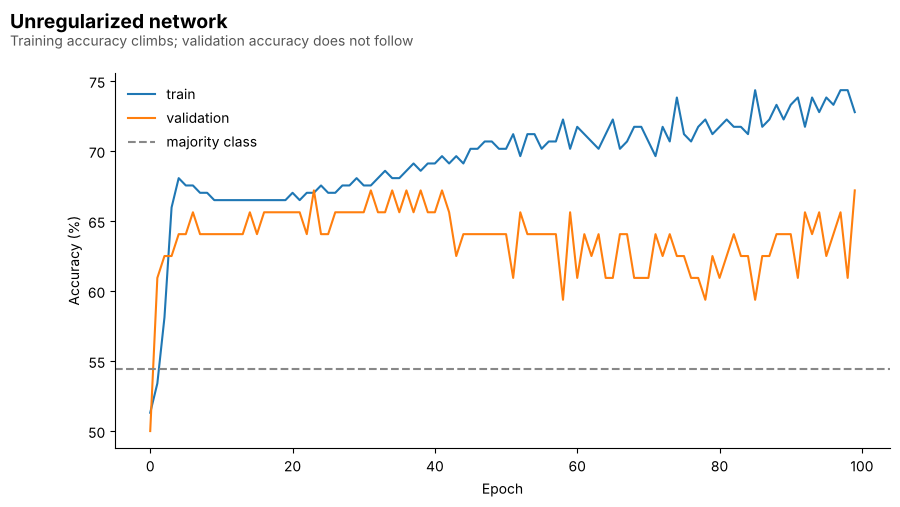

In [16]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(base_train_accs, label="train")
ax.plot(base_val_accs, label="validation")
ax.axhline(max(y_train.mean(), 1 - y_train.mean()) * 100,
           color="#888888", linestyle="--", label="majority class")
ax.set_xlabel("Epoch")
ax.set_ylabel("Accuracy (%)")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
fig.subplots_adjust(top=0.86)
fig.text(0.02, 0.95, "Unregularized network", fontsize=14, weight="bold")
fig.text(0.02, 0.915, "Training accuracy climbs; validation accuracy does not follow",
         fontsize=10, color="#555555")
plt.show()

The training curve pulls away from the validation curve and keeps going. The
validation curve is flat and noisy, bouncing by several points between epochs
because one validation row is worth 1.56 percentage points, so a wobble of
three points is two rows changing their minds.

## 8. Regularization and early stopping

In [17]:
torch.manual_seed(SEED)
reg_model = nn.Sequential(
    nn.Linear(len(FEATURES), 32), nn.BatchNorm1d(32), nn.ReLU(), nn.Dropout(0.3),
    nn.Linear(32, 16), nn.BatchNorm1d(16), nn.ReLU(), nn.Dropout(0.2),
    nn.Linear(16, 8), nn.ReLU(),
    nn.Linear(8, 1), nn.Sigmoid(),
)

criterion = nn.BCELoss()
optimizer = optim.Adam(reg_model.parameters(), lr=0.001)

best_val, best_epoch, patience, counter, best_state = 0.0, 0, 15, 0, None
reg_train_accs, reg_val_accs = [], []

for epoch in range(100):
    reg_model.train()
    for bx, by in train_loader:
        optimizer.zero_grad()
        loss = criterion(reg_model(bx).squeeze(), by)
        loss.backward()
        optimizer.step()
    tr = accuracy(reg_model, X_train_t, y_train_t)
    va = accuracy(reg_model, X_val_t, y_val_t)
    reg_train_accs.append(tr)
    reg_val_accs.append(va)
    if va > best_val:
        best_val, best_epoch, counter = va, epoch, 0
        best_state = copy.deepcopy(reg_model.state_dict())
    else:
        counter += 1
    if counter >= patience:
        print("early stop at epoch %d" % (epoch + 1))
        break

reg_model.load_state_dict(best_state)
print("best epoch %d   best val %.2f" % (best_epoch + 1, best_val))
print()
print("restored model:  train %.2f   val %.2f   gap %.2f"
      % (accuracy(reg_model, X_train_t, y_train_t),
         accuracy(reg_model, X_val_t, y_val_t),
         accuracy(reg_model, X_train_t, y_train_t) - accuracy(reg_model, X_val_t, y_val_t)))
print("test %.2f" % accuracy(reg_model, X_test_t, y_test_t))

early stop at epoch 40
best epoch 25   best val 70.31

restored model:  train 65.97   val 70.31   gap -4.34
test 62.50


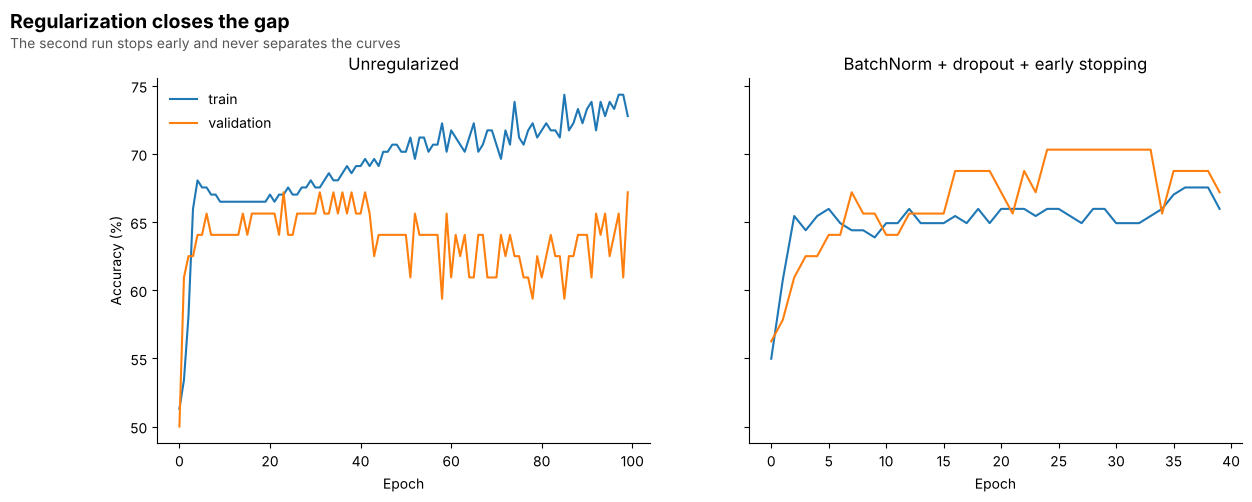

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, (tr, va, title) in zip(axes, [
        (base_train_accs, base_val_accs, "Unregularized"),
        (reg_train_accs, reg_val_accs, "BatchNorm + dropout + early stopping")]):
    ax.plot(tr, label="train")
    ax.plot(va, label="validation")
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Accuracy (%)")
axes[0].legend(frameon=False)
fig.subplots_adjust(top=0.84)
fig.text(0.02, 0.94, "Regularization closes the gap", fontsize=14, weight="bold")
fig.text(0.02, 0.90, "The second run stops early and never separates the curves",
         fontsize=10, color="#555555")
plt.show()

Note the restored model's gap is slightly negative: validation accuracy edges
above training accuracy. That is not a bug. Dropout is active during training
and disabled in `eval()` mode, so the training accuracy reported here is
measured on a network that was learning under handicap. A small negative gap is
the expected signature of regularization doing its job.

## 9. Test set evaluation

In [19]:
reg_model.eval()
with torch.no_grad():
    test_probs = reg_model(X_test_t).squeeze()
    test_preds = (test_probs > 0.5).float()

cm = confusion_matrix(y_test_t.numpy(), test_preds.numpy())
tn, fp, fn, tp = cm.ravel()

test_accuracy = (test_preds == y_test_t).float().mean().item() * 100
precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0

print("confusion matrix [[tn fp] [fn tp]]")
print(cm)
print()
print("true negatives  %3d    false positives %3d" % (tn, fp))
print("false negatives %3d    true positives  %3d" % (fn, tp))
print()
print("test accuracy %.2f%%" % test_accuracy)
print("precision     %.4f" % precision)
print("recall        %.4f" % recall)
print()
print("predicted-positive rate %.4f versus actual %.4f"
      % (test_preds.mean().item(), y_test_t.mean().item()))

confusion matrix [[tn fp] [fn tp]]
[[23  6]
 [18 17]]

true negatives   23    false positives   6
false negatives  18    true positives   17

test accuracy 62.50%
precision     0.7391
recall        0.4857

predicted-positive rate 0.3594 versus actual 0.5469


### Reading this as an investment desk

Precision and recall point in opposite directions here, and the asymmetry is
the useful part.

**Precision is high.** When the model says an IPO will list at a gain it is
right about three quarters of the time, against a base rate of 55%. A
recommendation from this model is meaningfully better than the average IPO.

**Recall is low.** It catches under half of the winners, so most profitable
IPOs are passed over.

The model predicts "profitable" far less often than the base rate: it is
reluctant to call a winner. For a desk deploying capital that is the less
damaging way to be wrong. A false positive is money placed into an IPO that
lists down, and the loss is realized. A false negative is an opportunity not
taken, which costs the spread but not the capital. A model that is picky and
usually right when it speaks is more useful than one that flags everything.

The caveat is that none of this is free: a strategy acting only on this
model's positives would participate in about a third of IPOs. Whether that is
worth the research overhead is a business question, not a modelling one.

## 10. Was the deep network worth it?

Everything above follows the brief and produces a plausible-looking result. Now
the question the brief does not ask.

Two things make the single number above untrustworthy:

1. **The test set holds 64 rows.** One prediction moves accuracy by 1.56
   percentage points, and the 95% confidence interval around any accuracy here
   is roughly ±12 points.
2. **One split is one draw.** The split is random. A different `random_state`
   gives a different test set, and with 64 rows that matters.

So the whole pipeline is rerun across ten random splits, with a logistic
regression fitted on the identical splits and scaling for comparison.

In [20]:
def run_split(seed):
    """Full pipeline on one random split. Returns (net, logreg, majority)."""
    torch.manual_seed(seed)
    np.random.seed(seed)

    Xt, Xs, yt, ys = train_test_split(
        X, y, test_size=0.2, stratify=y, random_state=seed)
    Xa, Xv, ya, yv = train_test_split(
        Xt, yt, test_size=0.25, stratify=yt, random_state=seed)

    sc = StandardScaler().fit(Xa)
    A = torch.tensor(sc.transform(Xa), dtype=torch.float32)
    V = torch.tensor(sc.transform(Xv), dtype=torch.float32)
    T = torch.tensor(sc.transform(Xs), dtype=torch.float32)
    ta = torch.tensor(ya, dtype=torch.float32)
    tv = torch.tensor(yv, dtype=torch.float32)
    ts = torch.tensor(ys, dtype=torch.float32)

    loader = DataLoader(TensorDataset(A, ta), batch_size=16, shuffle=True)

    torch.manual_seed(seed)
    net = nn.Sequential(
        nn.Linear(len(FEATURES), 32), nn.BatchNorm1d(32), nn.ReLU(), nn.Dropout(0.3),
        nn.Linear(32, 16), nn.BatchNorm1d(16), nn.ReLU(), nn.Dropout(0.2),
        nn.Linear(16, 8), nn.ReLU(),
        nn.Linear(8, 1), nn.Sigmoid(),
    )
    crit = nn.BCELoss()
    opt = optim.Adam(net.parameters(), lr=0.001)

    best, state, wait = 0.0, None, 0
    for _ in range(100):
        net.train()
        for bx, by in loader:
            opt.zero_grad()
            crit(net(bx).squeeze(), by).backward()
            opt.step()
        va = accuracy(net, V, tv)
        if va > best:
            best, state, wait = va, copy.deepcopy(net.state_dict()), 0
        else:
            wait += 1
        if wait >= 15:
            break
    net.load_state_dict(state)

    logreg = LogisticRegression(max_iter=1000).fit(sc.transform(Xa), ya)
    return (accuracy(net, T, ts),
            logreg.score(sc.transform(Xs), ys) * 100,
            max(ys.mean(), 1 - ys.mean()) * 100)


SEEDS = [0, 1, 2, 7, 13, 21, 42, 99, 123, 2024]
results = [run_split(s) for s in SEEDS]

net_scores = np.array([r[0] for r in results])
lr_scores = np.array([r[1] for r in results])
maj_scores = np.array([r[2] for r in results])

print("seed    network  logreg  majority")
for s, r in zip(SEEDS, results):
    print("%-7d %7.2f %7.2f %9.2f" % (s, r[0], r[1], r[2]))
print()
print("network  mean %.2f  sd %.2f  range %.2f to %.2f"
      % (net_scores.mean(), net_scores.std(), net_scores.min(), net_scores.max()))
print("logreg   mean %.2f  sd %.2f  range %.2f to %.2f"
      % (lr_scores.mean(), lr_scores.std(), lr_scores.min(), lr_scores.max()))
print("majority mean %.2f" % maj_scores.mean())

seed    network  logreg  majority
0         68.75   68.75     54.69
1         64.06   57.81     54.69
2         59.38   57.81     54.69
7         65.62   75.00     54.69
13        70.31   70.31     54.69
21        64.06   64.06     54.69
42        62.50   62.50     54.69
99        60.94   68.75     54.69
123       56.25   62.50     54.69
2024      57.81   59.38     54.69

network  mean 62.97  sd 4.31  range 56.25 to 70.31
logreg   mean 64.69  sd 5.51  range 57.81 to 75.00
majority mean 54.69


In [21]:
print("network beats logistic regression in %d of %d splits"
      % ((net_scores > lr_scores).sum(), len(SEEDS)))
print("network beats the majority baseline in %d of %d splits"
      % ((net_scores > maj_scores).sum(), len(SEEDS)))
print()

p = 0.625
half_width = 1.96 * math.sqrt(p * (1 - p) / len(X_test)) * 100
print("95%% confidence interval on a 62.5%% accuracy over %d test rows: +/- %.2f points"
      % (len(X_test), half_width))
print("mean gap between the two models: %.2f points"
      % abs(net_scores.mean() - lr_scores.mean()))
print("that gap is %.1f test predictions"
      % (abs(net_scores.mean() - lr_scores.mean()) / (100 / len(X_test))))

network beats logistic regression in 2 of 10 splits
network beats the majority baseline in 10 of 10 splits

95% confidence interval on a 62.5% accuracy over 64 test rows: +/- 11.86 points
mean gap between the two models: 1.72 points
that gap is 1.1 test predictions


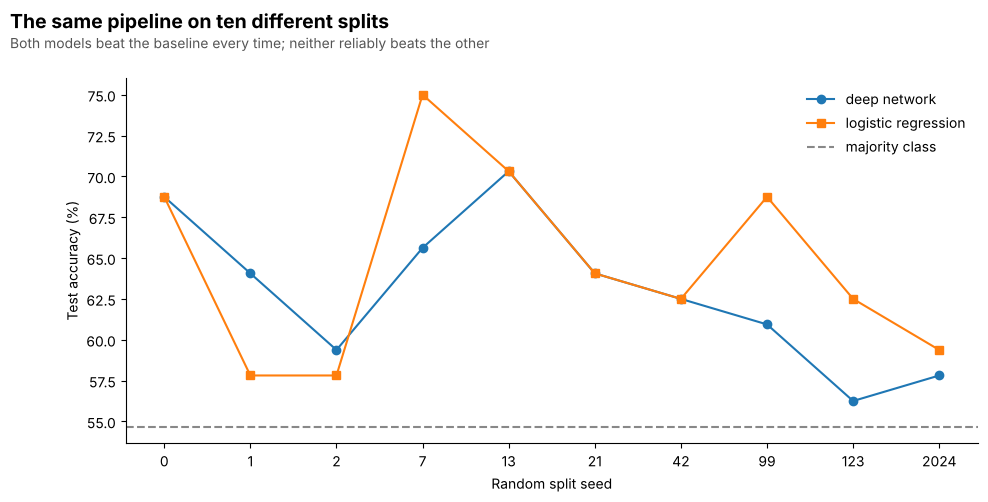

In [22]:
fig, ax = plt.subplots(figsize=(11, 5))
positions = np.arange(len(SEEDS))
ax.plot(positions, net_scores, "o-", label="deep network")
ax.plot(positions, lr_scores, "s-", label="logistic regression")
ax.axhline(maj_scores.mean(), color="#888888", linestyle="--",
           label="majority class")
ax.set_xticks(positions)
ax.set_xticklabels(SEEDS)
ax.set_xlabel("Random split seed")
ax.set_ylabel("Test accuracy (%)")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
fig.subplots_adjust(top=0.84)
fig.text(0.02, 0.94, "The same pipeline on ten different splits",
         fontsize=14, weight="bold")
fig.text(0.02, 0.90,
         "Both models beat the baseline every time; neither reliably beats the other",
         fontsize=10, color="#555555")
plt.show()

## Conclusions

**The features carry real signal.** Both models beat the majority-class
baseline on every one of the ten splits. Subscription demand, particularly from
institutional buyers, genuinely does predict the direction of first-day
movement. That is the finding worth keeping.

**The deep network is not the reason.** It loses to logistic regression on most
splits and has a lower mean accuracy. Six features and 191 training rows do not
contain enough structure to need a 1,000-parameter network, and the funnel
architecture spends its capacity memorizing instead. Regularization closes the
train/validation gap but does not create information that is not there.

**One number from one split should not be trusted.** The spread across seeds is
several points wide, and the confidence interval on any single test accuracy is
about ±12 points on 64 rows. The difference between the two models is smaller
than one test prediction. Had this notebook stopped at section 9 it would have
reported a single accuracy with an implied precision the data cannot support.

**What would actually improve this**, in order of expected value: more rows,
since 319 IPOs is the binding constraint on everything above; a time-ordered
split rather than a random one, because predicting past IPOs from future ones
is not the deployed problem and a random split quietly allows it; and sector
and market-condition features, since whether an IPO pops on day one depends
heavily on the market it lists into, which none of these six columns observe.